# 07 · Advection: the hard case

Advection u_t + a u_x = 0 moves a profile without changing it, and that is exactly what discretisations find
hard: the centred stencil conserves the shape but is unstable with any explicit integrator whose stability
region excludes the imaginary axis; the upwind stencil is stable but smears everything it carries; higher-order
stencils oscillate at jumps. This notebook measures these behaviours, derives them from modified equations,
and shows the way out - flux limiters - before applying it to a reactor with inflow and outflow boundaries.

**What you will learn**
- explain why centred stencils need integrators that cover the imaginary axis
- derive and verify numerical diffusion from the modified equation
- use flux limiters and the TVD property
- impose inflow conditions and Danckwerts boundaries

**Before you start:** notebook 02  ·  **Time:** about 75 min

In [1]:
try:                      # on Google Colab (or anywhere engmolines is missing): install it from GitHub
    import engmolines
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engmolines"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engmolines import problems as pr, integrators as ti, analysis, stiffness, grids, boundary as bc, operators as op
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Four schemes, one pulse

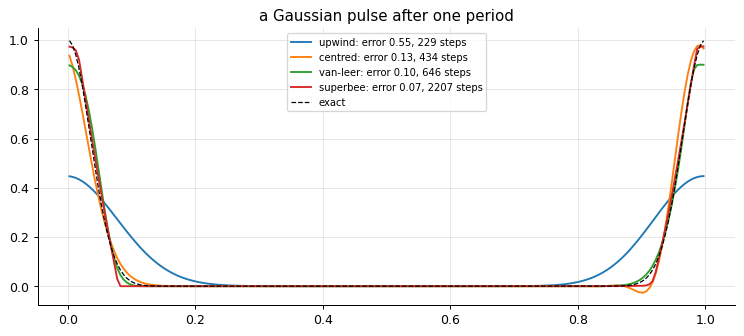

In [2]:
fig, ax = plt.subplots(figsize=(10, 4))
for sch in ("upwind", "centred", "van-leer", "superbee"):
    p = pr.advection_periodic(scheme=sch)
    s = p.solve("dopri", rtol=1e-7, atol=1e-9)
    ax.plot(p.x, s.y[-1], label=f"{sch}: error {p.error(s):.2f}, {s.steps} steps")
ax.plot(p.x, p.exact(p.x, p.t_end), "k--", lw=1, label="exact"); ax.legend(fontsize=8); ax.set_title("a Gaussian pulse after one period"); plt.show()

After one period the exact solution is the initial pulse. Upwind has flattened it (error 0.55); centred keeps
the height but trails wiggles (0.13); the limited schemes keep both height and shape (0.07-0.10). The adaptive
integrator's step counts also differ: the limited schemes are nonlinear and cost more evaluations.

## Why centred differences fail with explicit Euler, and why upwind smears

centred: eigenvalues are purely imaginary (max |Re| = 3.2e-10), up to +-i a/dx = 200
   explicit Euler step limit: 7.1e-09; RK4: 0.0141 (= 2.83 dx/a)
upwind: eigenvalues on a circle of radius a/dx centred at -a/dx: real parts from -400 to -0.0; Euler limit 0.0050 (= dx/a, the CFL condition)

modified equation of upwind: u_t + a u_x = (a dx/2) u_xx + ...: numerical diffusion 0.0025


predicted peak after one period 0.05/sigma = 0.447; computed 0.447


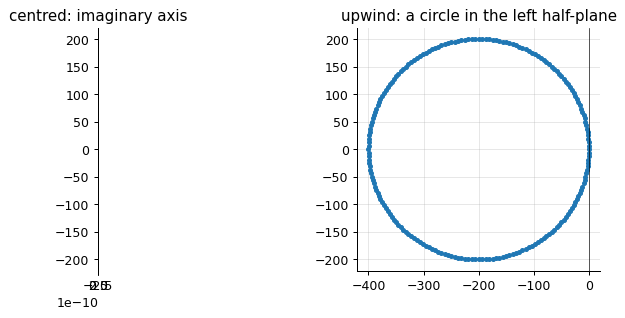

In [3]:
p = pr.advection_periodic(scheme="centred")
lam = stiffness.spectrum(p.rhs, p.y0)
print(f"centred: eigenvalues are purely imaginary (max |Re| = {np.max(np.abs(lam.real)):.1e}), up to +-i a/dx = {1 / p.grid.dx:.0f}")
print(f"   explicit Euler step limit: {stiffness.explicit_step_limit(lam, 'euler'):.1e}; RK4: {stiffness.explicit_step_limit(lam, 'rk4'):.4f} (= 2.83 dx/a)")
pu = pr.advection_periodic(scheme="upwind")
lamu = stiffness.spectrum(pu.rhs, pu.y0)
print(f"upwind: eigenvalues on a circle of radius a/dx centred at -a/dx: real parts from {lamu.real.min():.0f} to {lamu.real.max():.1f}; Euler limit {stiffness.explicit_step_limit(lamu, 'euler'):.4f} (= dx/a, the CFL condition)")
me = analysis.modified_equation("upwind", 1.0, p.grid.dx)
print(f"\nmodified equation of upwind: u_t + a u_x = (a dx/2) u_xx + ...: numerical diffusion {me['diffusion']:.4f}")
s = pu.solve("dopri", rtol=1e-9, atol=1e-11)
sig = np.sqrt(0.05**2 + 4 * me['diffusion'] * 1.0)
print(f"predicted peak after one period 0.05/sigma = {0.05 / sig:.3f}; computed {s.y[-1].max():.3f}")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(lam.real, lam.imag, "."); axes[0].set_title("centred: imaginary axis"); axes[1].plot(lamu.real, lamu.imag, "."); axes[1].set_title("upwind: a circle in the left half-plane")
for ax in axes: ax.set_aspect("equal"); ax.axvline(0, color="k", lw=0.5)
plt.show()

The centred operator is antisymmetric: its eigenvalues lie on the imaginary axis, where explicit Euler's
stability region has no interior - every mode grows - while RK4's region reaches ±2.83i, so RK4 and
Dormand-Prince are stable up to a Courant number of 2.8 (in the method of lines; the fully discrete CFL limit
is a property of the pair). Upwind's eigenvalues lie on a circle inside the left half-plane: stable with Euler up
to Courant number 1, but every mode decays - the modified equation u_t + a u_x = (aΔx/2) u_xx says upwind
solves the advection-diffusion equation, and the predicted spreading of the Gaussian matches to three digits.

## Flux limiters: second order where it helps, monotone where it must

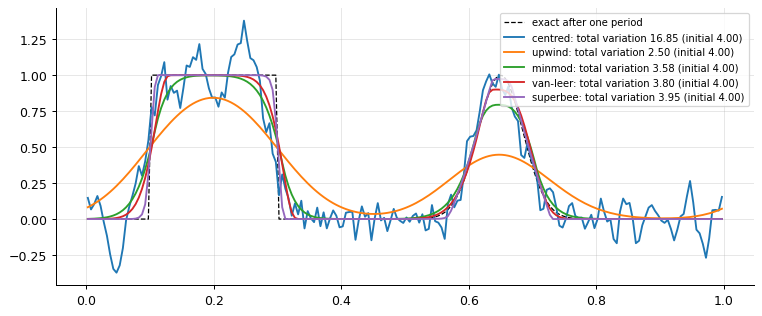

In [4]:
g = grids.cell_centred(0, 1, 200)
sq = np.where((g.x > 0.1) & (g.x < 0.3), 1.0, 0.0) + np.exp(-((g.x - 0.65) / 0.05) ** 2)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(g.x, sq, "k--", lw=1, label="exact after one period")
for sch in ("centred", "upwind", "minmod", "van-leer", "superbee"):
    f = lambda t, u, sch=sch: op.advection(u, g, 1.0, bc.Periodic(), bc.Periodic(), t, sch)
    s = ti.dopri45(f, sq, (0, 1.0), 1e-7, 1e-9, n_out=1)
    tv = np.sum(np.abs(np.diff(np.r_[s.y[-1], s.y[-1][0]])))
    ax.plot(g.x, s.y[-1], label=f"{sch}: total variation {tv:.2f} (initial 4.00)")
ax.legend(fontsize=8); plt.show()

On a square wave plus a Gaussian the centred scheme oscillates (its total variation grows from 4 to over 5),
upwind smears, and the limited schemes are *total-variation diminishing*: they switch to upwind at the jumps and
to second order in the smooth parts. Minmod is the most cautious, superbee the sharpest (it keeps the square
wave almost intact but squares off the Gaussian's peak), van Leer a balance. Godunov's theorem says no linear
scheme can be both second order and monotone; the limiters escape it by being nonlinear.

## Boundaries: an inflow, and a reactor with Danckwerts conditions

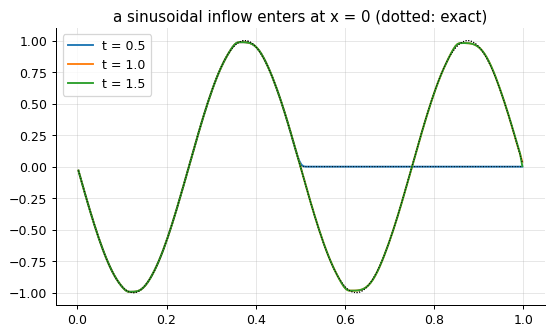

inflow problem: max error 0.027 (one boundary condition only: at the inflow; the outflow needs none)


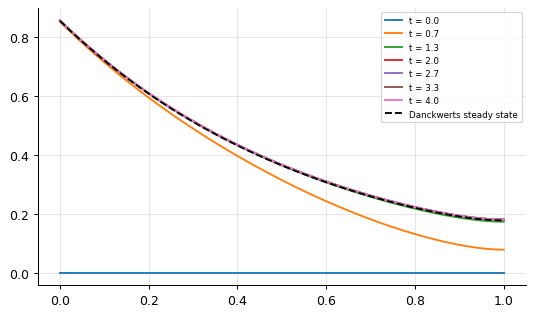

outlet conversion 0.8198 (exact 0.8227); the inlet jump c(0+) < 1 is the Danckwerts condition c - c_x/Pe = 1


In [5]:
p = pr.advection_inflow()
s = p.solve("dopri", rtol=1e-7, atol=1e-9, n_out=3)
for t, y in zip(s.t[1:], s.y[1:]):
    plt.plot(p.x, y, label=f"t = {t:.1f}"); plt.plot(p.x, p.exact(p.x, t), "k:", lw=0.8)
plt.legend(); plt.title("a sinusoidal inflow enters at x = 0 (dotted: exact)"); plt.show()
print(f"inflow problem: max error {p.error(s):.3f} (one boundary condition only: at the inflow; the outflow needs none)")
p = pr.plug_flow_reactor(Pe=10.0, Da=2.0)
s = p.solve("bdf", 0.01, order=2, n_out=6)
for t, y in zip(s.t, s.y):
    plt.plot(p.x, y, label=f"t = {t:.1f}")
plt.plot(p.x, p.exact(p.x), "k--", label="Danckwerts steady state"); plt.legend(fontsize=7); plt.show()
print(f"outlet conversion {1 - s.y[-1][-1]:.4f} (exact {p.params['conversion']:.4f}); the inlet jump c(0+) < 1 is the Danckwerts condition c - c_x/Pe = 1")

A hyperbolic equation takes its boundary condition where the characteristics enter: at the inflow only; the
outflow is left alone (a zero-gradient ghost), and imposing a value there would be inconsistent. The dispersed
plug-flow reactor adds a little diffusion and the Danckwerts conditions - a Robin condition at the inlet,
whose signature is the jump of the concentration below the feed value, and zero gradient at the outlet - and
reaches the classic closed-form steady conversion.

## Inside the algorithm: the upwind symbol and its circle

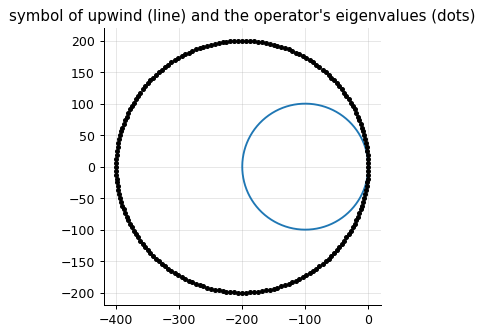

In [6]:
th = np.linspace(0, 2 * np.pi, 400)
sig = -analysis.symbol("first_upwind", th, p.grid.dx, 1.0)        # the operator is -a u_x
plt.plot(sig.real, sig.imag); plt.plot(lamu.real, lamu.imag, "k."); plt.gca().set_aspect("equal"); plt.title("symbol of upwind (line) and the operator's eigenvalues (dots)"); plt.show()

## Exercises
1. Compute the fully discrete amplification |R(h sigma(theta))| for upwind + Euler at Courant numbers 0.5, 1.0 and 1.1 with `analysis.amplification`, and for centred + RK4 at Courant numbers 2.5 and 3.0. Confirm the stability limits by integrating the pulse.
2. Reverse the flow in the plug-flow reactor (u = -1, feed at x = 1) and solve it; then set the feed concentration to a square pulse in time and watch it exit. What happens if you (wrongly) impose a Dirichlet value at the outflow?
3. **Implement it yourself:** write the second-order upwind-biased stencil (3 points upstream) and show from its modified equation that it is dispersive, not diffusive; measure the phase error of a sine wave after one period.